# Credit Scoring Models: German Credit
DSE4212/QF4212 Group Project 1

One notebook trains, tunes and evaluates all three models, then compares them:
**logistic regression**, **random forest** and **AdaBoost**.

Convention used everywhere: **positive class (1) = default / bad credit**.

**Contents**
1. Setup and data
2. Shared methodology (pipeline, cross-validation, class imbalance, thresholds)
3. Logistic regression: naive baseline, untuned reference, tuning
4. Random forest: untuned reference, tuning
5. AdaBoost: untuned reference, tuning
6. Test-set evaluation at three operating points (all models)
7. Interpretation and model comparison
8. Conclusions, then saved outputs

Run top to bottom (about 4 minutes on 8 cores). Requires scikit-learn ≥ 1.7.

## 1. Setup and data

In [1]:
import sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_curve, roc_auc_score, ConfusionMatrixDisplay
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict)

# Find the project root (the folder that contains src/) so `from src...` works
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.preprocessing import make_pipeline, check_inputs   # shared preprocessing
from src.evaluation import (evaluate, metrics_only, results_table,
                            f1_optimal_threshold, cost_min_threshold,
                            cost_optimal_threshold, bootstrap_auc_ci, RANDOM_STATE)

matplotlib.rcParams.update({'font.size': 12})

OUT = ROOT / "outputs"
for sub in ("models", "predictions", "results"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

TARGET = "credit_risk"   # 1 = default (bad), 0 = good
FN_COST = 5              # a missed default costs 5x a wrongly rejected good client

The team's fixed `train.csv` / `test.csv` split (800 / 200 rows, stratified, seed 4212). Every model is trained and tested on exactly the same rows.

In [2]:
train = pd.read_csv(OUT / "train.csv")
test = pd.read_csv(OUT / "test.csv")

y_train, y_test = train[TARGET].astype(int), test[TARGET].astype(int)
X_train, X_test = train.drop(columns=[TARGET]), test.drop(columns=[TARGET])

print("train:", X_train.shape, "| test:", X_test.shape)
print(f"Default rate: train {y_train.mean():.3f}, test {y_test.mean():.3f}")
check_inputs(X_train)   # raises if expected columns are missing

train: (800, 26) | test: (200, 26)
Default rate: train 0.300, test 0.300


## 2. Shared methodology
**Preprocessing.** Every model uses the shared `make_pipeline` from `src/preprocessing.py`: the 8
engineered features, one-hot encoding of categoricals and median/mode imputation. Numeric features are
standardised for logistic regression (`scale_numeric=True`) but not for the tree models, because
monotone rescaling does not change a tree split. Sensitive attributes (`gender_group`, `age_group`)
are never model inputs.

**Cross-validation.** Hyperparameters are tuned with `RepeatedStratifiedKFold` (5 folds × 2 repeats,
seed 4212) on the training set only, scored on ROC AUC. Each fold keeps the 70/30 class ratio and has
about 190 defaults, enough for a stable AUC. The repeat reduces the noise from a single split. ROC AUC
does not depend on a threshold and is not distorted by class imbalance. Train-fold AUC is also
recorded to check for overfitting.

**Class imbalance (30% defaults)** is handled at two levels:
1. *Training:* class reweighting (`class_weight`) is included in the tree models' grids and kept
   only if CV prefers it.
2. *Decision:* the classification threshold is set from **out-of-fold training predictions**, never
   from the test set. Three operating points are reported:
   - 0.5, the default
   - the F1-optimal threshold
   - the cost-optimal threshold, minimising `FN_COST`·FN + FP

**Evaluation.** Every model is scored once on the test set with the shared `evaluate()` function.

The helpers below implement these steps once, for all three models.

In [3]:
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)   # tuning
OOF_CV = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)               # thresholds


def tune(pipeline, param_grid, name):
    """Grid search on the training set (ROC AUC, repeated stratified CV). Returns (search, results)."""
    gs = GridSearchCV(pipeline, param_grid, scoring="roc_auc", cv=CV, n_jobs=-1,
                      refit=True, return_train_score=True)
    t0 = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        gs.fit(X_train, y_train)
    cvr = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score").reset_index(drop=True)
    print(f"{name}: {len(cvr)} settings x {CV.get_n_splits()} fits in {time.time() - t0:.0f}s")
    print(f"Best params: { {k.replace('classifier__', ''): v for k, v in gs.best_params_.items()} }")
    print(f"CV AUC {gs.best_score_:.4f} (+/- {cvr.loc[0, 'std_test_score']:.4f}) | "
          f"mean train-fold AUC {cvr.loc[0, 'mean_train_score']:.4f}")
    cols = [c for c in cvr if c.startswith("param_")] + ["mean_test_score", "std_test_score",
                                                         "mean_train_score"]
    display(cvr[cols].head(8).rename(columns=lambda c: c.replace("param_classifier__", "")))
    return gs, cvr


def operating_points(model, prefix, label):
    """Thresholds from out-of-fold training predictions, then a single test-set evaluation."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        oof = cross_val_predict(model, X_train, y_train, method="predict_proba", cv=OOF_CV)[:, 1]
    pd.DataFrame({"index": X_train.index, "y_true": y_train.values, "y_proba": oof}).to_csv(
        OUT / f"predictions/{prefix}_train_oof_proba.csv", index=False)

    t_f1 = f1_optimal_threshold(y_train, oof)
    t_cost = cost_min_threshold(y_train, oof, cost_fn=FN_COST)
    print(f"[{label}] F1-optimal threshold {t_f1:.3f} | cost-optimal threshold {t_cost:.3f}\n")

    op = {"oof": oof, "t_f1": t_f1, "t_cost": t_cost}
    op["res_05"] = evaluate(model, X_test, y_test, threshold=0.5, name=f"{label} tuned @ 0.5",
                            fn_cost=FN_COST, save_to=str(OUT / f"predictions/{prefix}_test_proba.csv"))
    op["res_f1"] = evaluate(model, X_test, y_test, threshold=t_f1,
                            name=f"{label} tuned @ F1-optimal", fn_cost=FN_COST)
    op["res_cost"] = evaluate(model, X_test, y_test, threshold=t_cost,
                              name=f"{label} tuned @ cost-optimal", fn_cost=FN_COST)
    op["ci"] = bootstrap_auc_ci(y_test, op["res_05"]["y_proba"])
    print(f"\nTest AUC = {op['res_05']['auc']:.3f}, 95% bootstrap CI "
          f"[{op['ci'][0]:.3f}, {op['ci'][1]:.3f}]")
    return op


def plot_operating_points(op, roc_models, title, fname):
    """ROC (test), out-of-fold probability histogram with thresholds, confusion matrix at cost-opt."""
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    for res, lab in roc_models:
        fpr, tpr, _ = roc_curve(y_test, res["y_proba"])
        axes[0].plot(fpr, tpr, label=f"{lab} (AUC = {res['auc']:.3f})")
    axes[0].plot([0, 1], [0, 1], "--", color="gray")
    axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title=f"{title}: ROC - test set")
    axes[0].legend(loc="lower right"); axes[0].grid(alpha=0.3)

    bins = np.linspace(0, 1, 41)
    axes[1].hist(op["oof"][y_train == 0], bins=bins, alpha=0.6, label="good")
    axes[1].hist(op["oof"][y_train == 1], bins=bins, alpha=0.6, label="default")
    for t, ls, lab in [(0.5, ":", "0.5"), (op["t_f1"], "--", "F1-opt"), (op["t_cost"], "-", "cost-opt")]:
        axes[1].axvline(t, color="k", ls=ls, lw=1, label=f"{lab} = {t:.2f}")
    axes[1].set(xlabel="Predicted P(default)", ylabel="Count", title="Out-of-fold probabilities (train)")
    axes[1].legend()

    ConfusionMatrixDisplay(op["res_cost"]["confusion_matrix"], display_labels=["good", "default"]).plot(
        ax=axes[2], colorbar=False, cmap="Blues")
    axes[2].set_title(f"Confusion matrix (threshold {op['t_cost']:.3f})")
    plt.tight_layout()
    plt.savefig(OUT / f"results/{fname}", dpi=200)
    plt.show()

## 3. Logistic regression
### 3.1 Naive baseline (Chapter 6 approach)
A plain `LogisticRegression()` on 7 numeric columns only, with no scaling, no categorical variables and
no tuning, as fitted in class. It is repeated here on the shared split so it is directly comparable.

In [4]:
naive_features = ["log1p_credit_amount", "log1p_duration_months", "installment_rate",
                  "residence_since", "age_years", "existing_credits", "people_liable"]

naive = LogisticRegression(max_iter=1000)
naive.fit(X_train[naive_features], y_train)
res_naive = evaluate(naive, X_test[naive_features], y_test,
                     name="Naive LR (7 numeric features)", fn_cost=FN_COST, report=True)

=== Naive LR (7 numeric features) | threshold = 0.500 ===
AUC 0.6798 | Precision 0.8333 | Recall 0.0833 | F1 0.1515 | Accuracy 0.7200
          pred 0  pred 1
actual 0     139       1
actual 1      55       5
              precision    recall  f1-score   support

           0       0.72      0.99      0.83       140
           1       0.83      0.08      0.15        60

    accuracy                           0.72       200
   macro avg       0.77      0.54      0.49       200
weighted avg       0.75      0.72      0.63       200



**Remark.** Accuracy looks acceptable only because 70% of clients are good: predicting
"good" for everyone already scores 0.70. The recall on defaults and the AUC are the
informative numbers, and both are weak.

### 3.2 Untuned reference (shared pipeline)
The untuned `LogisticRegression(max_iter=1000)` (C = 1, L2 penalty) on the full shared pipeline.

In [5]:
lr_default = make_pipeline(LogisticRegression(max_iter=1000), scale_numeric=True)
lr_default.fit(X_train, y_train)
res_lr_default = evaluate(lr_default, X_test, y_test, name="LR untuned (C=1, L2)", fn_cost=FN_COST)

=== LR untuned (C=1, L2) | threshold = 0.500 ===
AUC 0.8150 | Precision 0.6809 | Recall 0.5333 | F1 0.5981 | Accuracy 0.7850
          pred 0  pred 1
actual 0     125      15
actual 1      28      32


### 3.3 Tuning
Grid: `C` (inverse regularisation strength, 11 log-spaced values from 0.001 to 100) × `l1_ratio`
(0 = ridge, 0.5 = elastic net, 1 = lasso), with the SAGA solver. `penalty="elasticnet"` is set
explicitly so that `l1_ratio` takes effect in every scikit-learn version. With `l1_ratio = 0` this
is the ordinary L2 (ridge) model. Class imbalance is handled by the threshold (Section 6).

In [6]:
lr_base = make_pipeline(
    LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.0, max_iter=20000,
                       random_state=RANDOM_STATE),
    scale_numeric=True,
)
lr_grid = {
    "classifier__C": np.logspace(-3, 2, 11),
    "classifier__l1_ratio": [0.0, 0.5, 1.0],
}
gs_lr, cvr_lr = tune(lr_base, lr_grid, "Logistic regression")
lr_best = gs_lr.best_estimator_

Logistic regression: 33 settings x 10 fits in 17s
Best params: {'C': np.float64(0.03162277660168379), 'l1_ratio': 0.0}
CV AUC 0.7692 (+/- 0.0338) | mean train-fold AUC 0.8178


,C,l1_ratio,mean_test_score,std_test_score,mean_train_score
0,0.031623,0.0,0.769178,0.033816,0.817784
1,0.100000,0.0,0.768341,0.029836,0.829146
2,0.316228,0.5,0.765551,0.027610,0.830664
3,0.316228,0.0,0.763839,0.026690,0.836085
4,0.010000,0.0,0.761403,0.037001,0.801338
5,0.316228,1.0,0.760063,0.029626,0.821702
6,1.000000,1.0,0.758966,0.024447,0.836611
7,1.000000,0.5,0.758854,0.025057,0.838224


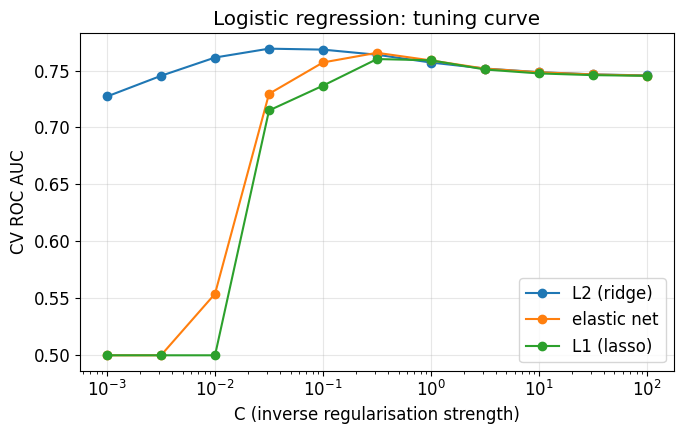

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
names = {0.0: "L2 (ridge)", 0.5: "elastic net", 1.0: "L1 (lasso)"}
for l1, g in cvr_lr.groupby("param_classifier__l1_ratio"):
    g = g.sort_values("param_classifier__C")
    ax.plot(g["param_classifier__C"].astype(float), g["mean_test_score"], marker="o", label=names[float(l1)])
ax.set_xscale("log")
ax.set(xlabel="C (inverse regularisation strength)", ylabel="CV ROC AUC",
       title="Logistic regression: tuning curve")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(OUT / "results/logreg_tuning_curve.png", dpi=200)
plt.show()

**Remark.** Strong regularisation (small C) with lasso or elastic net shrinks every coefficient
to zero and the AUC collapses to 0.5. Ridge is the most stable choice. The AUC is flat for moderate to
large C, so tuning gives only a small gain over the untuned model.

## 4. Random forest
### 4.1 Method and untuned reference
An average of many deep decision trees. Each tree is grown on a bootstrap sample of the rows and
chooses each split from a random subset of the features. Averaging de-correlated trees reduces
variance, and the trees capture non-linear effects and interactions (e.g. large loan *and* no
savings) without having to specify them.

The reference is scikit-learn's default forest: 500 fully grown trees with no class weighting.

In [8]:
rf_default = make_pipeline(RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE),
                           scale_numeric=False)
rf_default.fit(X_train, y_train)
res_rf_default = evaluate(rf_default, X_test, y_test, name="RF untuned (500 trees)", fn_cost=FN_COST)

=== RF untuned (500 trees) | threshold = 0.500 ===
AUC 0.8082 | Precision 0.7436 | Recall 0.4833 | F1 0.5859 | Accuracy 0.7950
          pred 0  pred 1
actual 0     130      10
actual 1      31      29


### 4.2 Tuning
The number of trees is fixed at 500: more trees never hurt a forest, they only reduce the noise.
The grid controls the complexity of each tree and the randomness between trees.

| Parameter | Values | Role |
|---|---|---|
| `max_depth` | 4, 6, 8, 12, None | tree depth (None = grow fully) |
| `min_samples_leaf` | 1, 3, 5, 10 | smallest allowed leaf; larger = smoother probabilities |
| `max_features` | sqrt, 0.33 | share of features tried at each split |
| `class_weight` | None, balanced_subsample | class-imbalance reweighting inside each bootstrap sample |

80 combinations × 10 fits = 800 forests.

In [9]:
rf_base = make_pipeline(RandomForestClassifier(n_estimators=500, n_jobs=1, random_state=RANDOM_STATE),
                        scale_numeric=False)
rf_grid = {
    "classifier__max_depth": [4, 6, 8, 12, None],
    "classifier__min_samples_leaf": [1, 3, 5, 10],
    "classifier__max_features": ["sqrt", 0.33],
    "classifier__class_weight": [None, "balanced_subsample"],
}
gs_rf, cvr_rf = tune(rf_base, rf_grid, "Random forest")
rf_best = gs_rf.best_estimator_

Random forest: 80 settings x 10 fits in 87s
Best params: {'class_weight': 'balanced_subsample', 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1}
CV AUC 0.7888 (+/- 0.0374) | mean train-fold AUC 0.9909


,class_weight,max_depth,max_features,min_samples_leaf,mean_test_score,std_test_score,mean_train_score
0,balanced_subsample,8,sqrt,1,0.788839,0.037353,0.990939
1,None,8,sqrt,1,0.788542,0.035113,0.989655
2,balanced_subsample,12,sqrt,1,0.788337,0.036960,0.999997
3,None,12,sqrt,1,0.785584,0.034214,0.999997
4,balanced_subsample,None,sqrt,1,0.785472,0.038981,1.000000
5,balanced_subsample,8,sqrt,3,0.785156,0.037221,0.970716
6,None,6,sqrt,3,0.784542,0.034022,0.929800
7,balanced_subsample,12,sqrt,3,0.784431,0.037290,0.990083


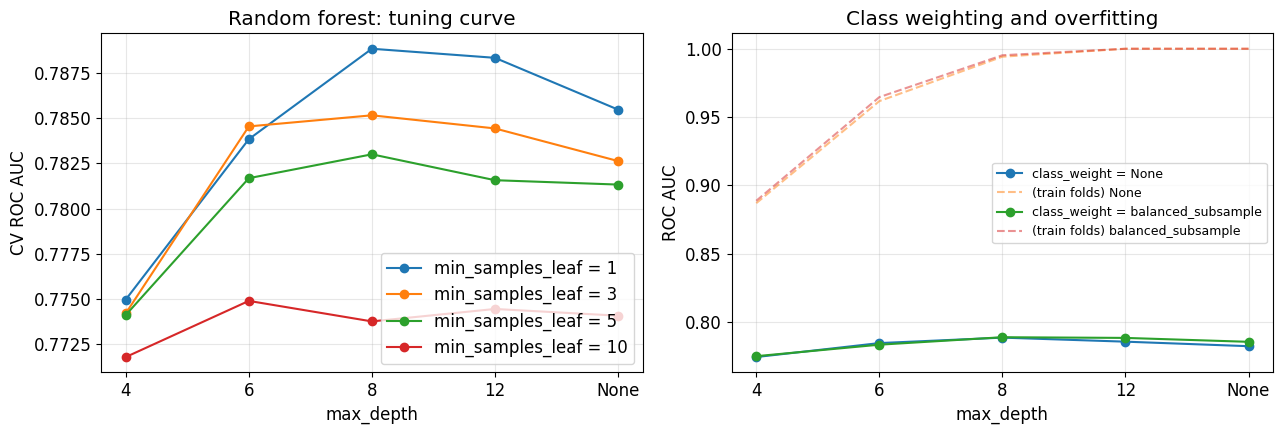

,best CV AUC,mean CV AUC over grid
weight,,
None,0.788542,0.775127
balanced_subsample,0.788839,0.777404


In [10]:
cvr_rf["depth"] = cvr_rf["param_classifier__max_depth"].apply(
    lambda d: "None" if d is None or pd.isna(d) else str(int(d)))
cvr_rf["weight"] = cvr_rf["param_classifier__class_weight"].apply(
    lambda w: "balanced_subsample" if w == "balanced_subsample" else "None")
depth_order = ["4", "6", "8", "12", "None"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for leaf, g in cvr_rf.groupby("param_classifier__min_samples_leaf"):
    s = g.groupby("depth")["mean_test_score"].max().reindex(depth_order)
    axes[0].plot(depth_order, s.values, marker="o", label=f"min_samples_leaf = {leaf}")
axes[0].set(xlabel="max_depth", ylabel="CV ROC AUC", title="Random forest: tuning curve")
axes[0].grid(alpha=0.3); axes[0].legend()

for w, g in cvr_rf.groupby("weight"):
    s = g.groupby("depth")["mean_test_score"].max().reindex(depth_order)
    axes[1].plot(depth_order, s.values, marker="o", label=f"class_weight = {w}")
    s_tr = g.groupby("depth")["mean_train_score"].max().reindex(depth_order)
    axes[1].plot(depth_order, s_tr.values, ls="--", alpha=0.5, label=f"(train folds) {w}")
axes[1].set(xlabel="max_depth", ylabel="ROC AUC", title="Class weighting and overfitting")
axes[1].grid(alpha=0.3); axes[1].legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUT / "results/rf_tuning_curve.png", dpi=200)
plt.show()

cvr_rf.groupby("weight")["mean_test_score"].agg(["max", "mean"]).rename(
    columns={"max": "best CV AUC", "mean": "mean CV AUC over grid"})

**Remark.** The best forest uses trees of depth 8, leaves of 1 row, √p features per split and
`balanced_subsample` weighting (CV AUC 0.789 ± 0.037). The tuning surface is flat. The top 10 settings are
within 0.005 AUC of each other, well inside one CV standard deviation, so the exact choice matters little.
Very shallow trees (depth 4) and large leaves (10) underfit. Train-fold AUC is ≈ 0.99, so each forest almost memorises its
training rows. This is normal for random forests, and CV AUC is the honest measure.

**Class weighting barely changes the AUC** (best 0.7888 weighted vs 0.7885 unweighted). This is expected.
Reweighting shifts the predicted probabilities upwards but hardly changes how borrowers are *ranked*.
Its practical effect is on the probability scale, which the threshold in Part 3 handles in either case.

## 5. AdaBoost
### 5.1 Method and untuned reference
**AdaBoost (SAMME)** fits a *sequence* of small trees. After each round, the rows the ensemble
misclassifies get more weight, so the next tree focuses on them. The final score is a weighted vote
of all trees. Where a random forest averages deep trees to reduce variance, boosting adds shallow
trees to reduce bias. The learning rate shrinks each tree's vote and trades off against the number
of rounds.

AdaBoost's `predict_proba` is a softmax of the weighted vote. These probabilities are **squeezed
towards 0.5** and not calibrated, so learning the threshold from data (Section 6) matters even more
than for the other models.

The reference is scikit-learn's default: 50 decision stumps (depth 1) with learning rate 1.

In [11]:
ada_default = make_pipeline(AdaBoostClassifier(random_state=RANDOM_STATE), scale_numeric=False)
ada_default.fit(X_train, y_train)
res_ada_default = evaluate(ada_default, X_test, y_test, name="AdaBoost untuned (50 stumps, lr=1)",
                           fn_cost=FN_COST)

=== AdaBoost untuned (50 stumps, lr=1) | threshold = 0.500 ===
AUC 0.8042 | Precision 0.6818 | Recall 0.5000 | F1 0.5769 | Accuracy 0.7800
          pred 0  pred 1
actual 0     126      14
actual 1      30      30


### 5.2 Tuning
| Parameter | Values | Role |
|---|---|---|
| `n_estimators` | 100, 300, 600 | boosting rounds |
| `learning_rate` | 0.03, 0.1, 0.3, 1.0 | shrinkage of each tree's vote |
| `estimator__max_depth` | 1, 2, 3 | base-tree depth (1 = stumps, additive model; 2–3 = interactions) |
| `estimator__class_weight` | None, balanced | class-imbalance reweighting in every boosting round |

72 combinations × 10 fits = 720 ensembles.

In [12]:
ada_base = make_pipeline(
    AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                       random_state=RANDOM_STATE),
    scale_numeric=False,
)
ada_grid = {
    "classifier__n_estimators": [100, 300, 600],
    "classifier__learning_rate": [0.03, 0.1, 0.3, 1.0],
    "classifier__estimator__max_depth": [1, 2, 3],
    "classifier__estimator__class_weight": [None, "balanced"],
}
gs_ada, cvr_ada = tune(ada_base, ada_grid, "AdaBoost")
ada_best = gs_ada.best_estimator_

AdaBoost: 72 settings x 10 fits in 46s
Best params: {'estimator__class_weight': None, 'estimator__max_depth': 2, 'learning_rate': 0.3, 'n_estimators': 300}
CV AUC 0.7682 (+/- 0.0274) | mean train-fold AUC 0.9088


,estimator__class_weight,estimator__max_depth,learning_rate,n_estimators,mean_test_score,std_test_score,mean_train_score
0,None,2,0.3,300,0.768211,0.027426,0.908811
1,None,2,0.3,600,0.766034,0.029381,0.927723
2,None,3,0.3,100,0.765067,0.040125,0.933919
3,None,2,1.0,100,0.764435,0.034819,0.945358
4,None,2,0.3,100,0.762733,0.022613,0.885161
5,None,2,0.1,600,0.760733,0.028033,0.892225
6,None,3,0.3,300,0.760621,0.036557,0.964215
7,None,3,0.3,600,0.759431,0.034616,0.988554


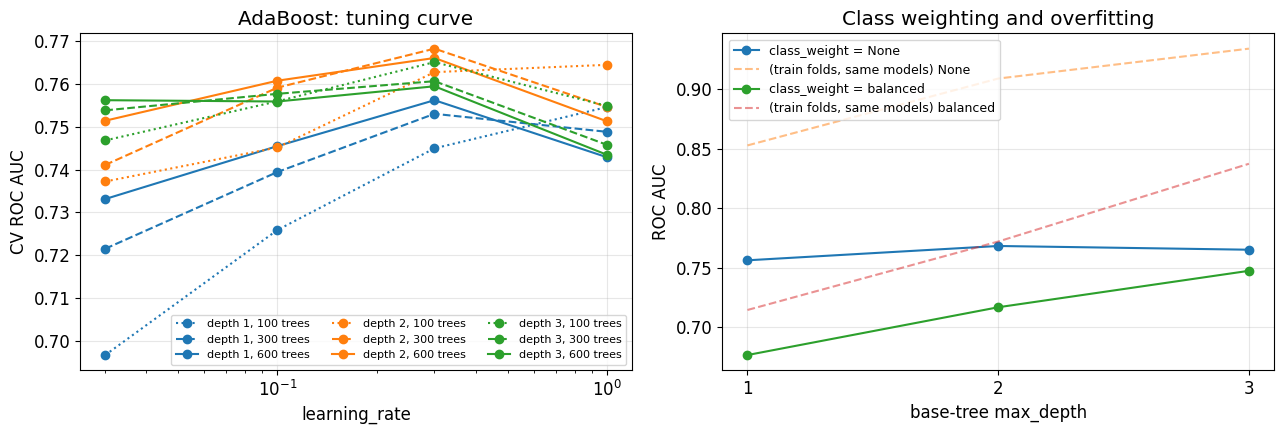

,best CV AUC,mean CV AUC over grid
weight,,
None,0.768211,0.749447
balanced,0.747359,0.705386


In [13]:
cvr_ada["weight"] = cvr_ada["param_classifier__estimator__class_weight"].apply(
    lambda w: "balanced" if w == "balanced" else "None")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for depth, g in cvr_ada.groupby("param_classifier__estimator__max_depth"):
    for n, gg in g.groupby("param_classifier__n_estimators"):
        s = gg.groupby("param_classifier__learning_rate")["mean_test_score"].max()
        axes[0].plot(s.index.astype(float), s.values, marker="o",
                     ls={100: ":", 300: "--", 600: "-"}[int(n)],
                     color={1: "C0", 2: "C1", 3: "C2"}[int(depth)],
                     label=f"depth {depth}, {n} trees")
axes[0].set_xscale("log")
axes[0].set(xlabel="learning_rate", ylabel="CV ROC AUC", title="AdaBoost: tuning curve")
axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8, ncol=3)

for w, g in cvr_ada.groupby("weight"):
    best_rows = g.loc[g.groupby("param_classifier__estimator__max_depth")["mean_test_score"].idxmax()]
    d = best_rows["param_classifier__estimator__max_depth"].astype(int)
    axes[1].plot(d, best_rows["mean_test_score"], marker="o", label=f"class_weight = {w}")
    axes[1].plot(d, best_rows["mean_train_score"], ls="--", alpha=0.5, label=f"(train folds, same models) {w}")
axes[1].set_xticks([1, 2, 3])
axes[1].set(xlabel="base-tree max_depth", ylabel="ROC AUC", title="Class weighting and overfitting")
axes[1].grid(alpha=0.3); axes[1].legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUT / "results/adaboost_tuning_curve.png", dpi=200)
plt.show()

cvr_ada.groupby("weight")["mean_test_score"].agg(["max", "mean"]).rename(
    columns={"max": "best CV AUC", "mean": "mean CV AUC over grid"})

**Remark.** The best AdaBoost uses depth-2 trees, learning rate 0.3, 300 rounds and **no class
weighting** (CV AUC 0.768 ± 0.027, train-fold AUC 0.909). Depth-2 trees beat stumps at almost every learning rate.
This suggests pairwise interactions carry signal, as the engineered interaction flags already hinted.
A learning rate of 1.0 overfits, and 0.03 would need more rounds than the grid allows.

**Class weighting clearly hurts AdaBoost** (best CV AUC 0.747 vs 0.768; mean over the grid 0.705 vs 0.749).
Boosting already reweights the rows it gets wrong, and those are disproportionately defaults.
Adding a fixed 2.3× class weight on top over-emphasises the minority class and makes the ensemble noisier.
For AdaBoost, imbalance is therefore handled only at the decision threshold.

## 6. Test-set evaluation at three operating points
For each tuned model: out-of-fold training predictions (5-fold stratified CV) give the F1-optimal
and cost-optimal thresholds. The test set is then scored **once** at 0.5 and at both thresholds.
Test-set probabilities are saved to `outputs/predictions/<model>_test_proba.csv`.

For calibrated probabilities, theory puts the cost-optimal threshold at 1/(1+5) ≈ 0.167. The learned thresholds differ because none of the models is perfectly calibrated.

### 6.1 Logistic regression

In [14]:
op_lr = operating_points(lr_best, "logreg", "LR")

[LR] F1-optimal threshold 0.304 | cost-optimal threshold 0.188

=== LR tuned @ 0.5 | threshold = 0.500 ===
AUC 0.8163 | Precision 0.7692 | Recall 0.3333 | F1 0.4651 | Accuracy 0.7700
          pred 0  pred 1
actual 0     134       6
actual 1      40      20
=== LR tuned @ F1-optimal | threshold = 0.304 ===
AUC 0.8163 | Precision 0.5679 | Recall 0.7667 | F1 0.6525 | Accuracy 0.7550
          pred 0  pred 1
actual 0     105      35
actual 1      14      46
=== LR tuned @ cost-optimal | threshold = 0.188 ===
AUC 0.8163 | Precision 0.4390 | Recall 0.9000 | F1 0.5902 | Accuracy 0.6250
          pred 0  pred 1
actual 0      71      69
actual 1       6      54



Test AUC = 0.816, 95% bootstrap CI [0.749, 0.877]


,Model / operating point,Threshold,AUC,Precision,Recall,F1,Accuracy,TN/FP/FN/TP,Cost (FN:FP = 5:1)
0,Naive LR (7 numeric features),0.500,0.680,0.833,0.083,0.152,0.720,139/1/55/5,276.0
1,"LR untuned (C=1, L2)",0.500,0.815,0.681,0.533,0.598,0.785,125/15/28/32,155.0
2,LR tuned @ 0.5,0.500,0.816,0.769,0.333,0.465,0.770,134/6/40/20,206.0
3,LR tuned @ F1-optimal,0.304,0.816,0.568,0.767,0.652,0.755,105/35/14/46,105.0
4,LR tuned @ cost-optimal,0.188,0.816,0.439,0.900,0.590,0.625,71/69/6/54,99.0


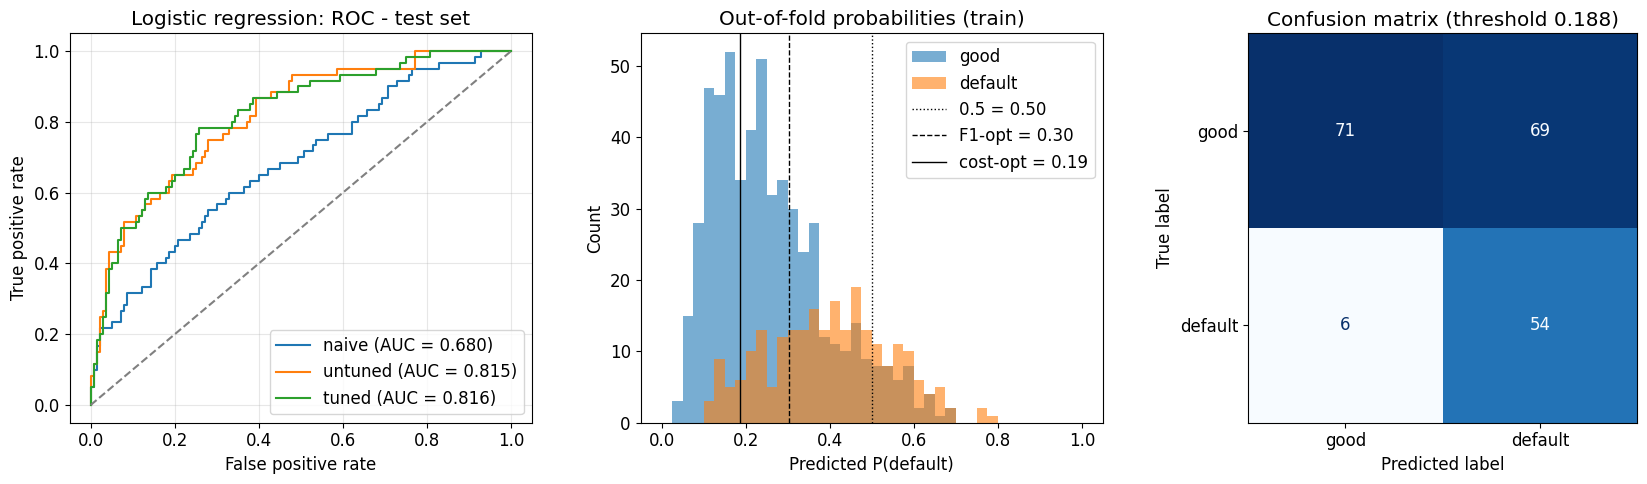

In [15]:
display(results_table([res_naive, res_lr_default, op_lr["res_05"], op_lr["res_f1"], op_lr["res_cost"]],
                      fn_cost=FN_COST))
plot_operating_points(op_lr, [(res_naive, "naive"), (res_lr_default, "untuned"), (op_lr["res_05"], "tuned")],
                      "Logistic regression", "logreg_roc_confusion.png")

**Remark.** Tuning barely changes the AUC, but the threshold changes the recall on defaults a lot.
At the cost-optimal threshold, logistic regression catches 54 of 60 defaulters (recall 0.90) at a
cost of 99, compared with 206 at 0.5.

### 6.2 Random forest

In [16]:
op_rf = operating_points(rf_best, "rf", "RF")

[RF] F1-optimal threshold 0.379 | cost-optimal threshold 0.274

=== RF tuned @ 0.5 | threshold = 0.500 ===
AUC 0.8026 | Precision 0.6316 | Recall 0.6000 | F1 0.6154 | Accuracy 0.7750
          pred 0  pred 1
actual 0     119      21
actual 1      24      36
=== RF tuned @ F1-optimal | threshold = 0.379 ===
AUC 0.8026 | Precision 0.5000 | Recall 0.7333 | F1 0.5946 | Accuracy 0.7000
          pred 0  pred 1
actual 0      96      44
actual 1      16      44
=== RF tuned @ cost-optimal | threshold = 0.274 ===
AUC 0.8026 | Precision 0.4264 | Recall 0.9167 | F1 0.5820 | Accuracy 0.6050
          pred 0  pred 1
actual 0      66      74
actual 1       5      55



Test AUC = 0.803, 95% bootstrap CI [0.733, 0.870]


,Model / operating point,Threshold,AUC,Precision,Recall,F1,Accuracy,TN/FP/FN/TP,Cost (FN:FP = 5:1)
0,RF untuned (500 trees),0.500,0.808,0.744,0.483,0.586,0.795,130/10/31/29,165.0
1,RF tuned @ 0.5,0.500,0.803,0.632,0.600,0.615,0.775,119/21/24/36,141.0
2,RF tuned @ F1-optimal,0.379,0.803,0.500,0.733,0.595,0.700,96/44/16/44,124.0
3,RF tuned @ cost-optimal,0.274,0.803,0.426,0.917,0.582,0.605,66/74/5/55,99.0


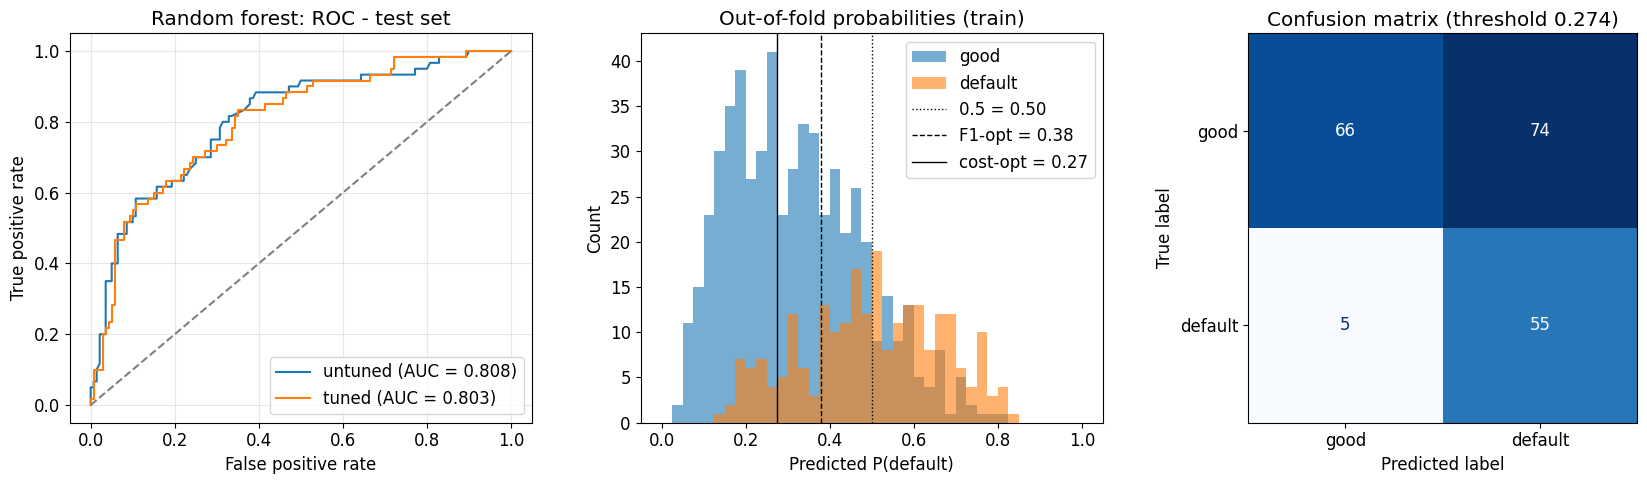

In [17]:
display(results_table([res_rf_default, op_rf["res_05"], op_rf["res_f1"], op_rf["res_cost"]], fn_cost=FN_COST))
plot_operating_points(op_rf, [(res_rf_default, "untuned"), (op_rf["res_05"], "tuned")],
                      "Random forest", "rf_roc_confusion.png")

**Remark.** Test AUC is 0.803 (95% CI 0.733–0.870), slightly below the untuned forest's 0.808.
With 200 test rows a 0.005 gap is noise. The tuned model was chosen on CV AUC, which is more reliable.
At 0.5 the tuned forest already catches more defaults than the untuned one (recall 0.60 vs 0.48)
because class weighting raises the predicted probabilities.

The cost-optimal threshold learned on the training folds is 0.274. That is above the 1/6 ≈ 0.167 that theory gives for calibrated
probabilities, because the forest's probabilities are neither calibrated nor on the unweighted scale.
At this threshold the forest catches **55 of 60 defaulters (recall 0.92)** and rejects 74 of 140 good clients.
The misclassification cost is **99**, down from 141 at 0.5.

### 6.3 AdaBoost

In [18]:
op_ada = operating_points(ada_best, "adaboost", "AdaBoost")

[AdaBoost] F1-optimal threshold 0.457 | cost-optimal threshold 0.364

=== AdaBoost tuned @ 0.5 | threshold = 0.500 ===
AUC 0.8176 | Precision 0.7500 | Recall 0.5000 | F1 0.6000 | Accuracy 0.8000
          pred 0  pred 1
actual 0     130      10
actual 1      30      30
=== AdaBoost tuned @ F1-optimal | threshold = 0.457 ===
AUC 0.8176 | Precision 0.5714 | Recall 0.6667 | F1 0.6154 | Accuracy 0.7500
          pred 0  pred 1
actual 0     110      30
actual 1      20      40
=== AdaBoost tuned @ cost-optimal | threshold = 0.364 ===
AUC 0.8176 | Precision 0.3972 | Recall 0.9333 | F1 0.5572 | Accuracy 0.5550
          pred 0  pred 1
actual 0      55      85
actual 1       4      56



Test AUC = 0.818, 95% bootstrap CI [0.748, 0.880]


,Model / operating point,Threshold,AUC,Precision,Recall,F1,Accuracy,TN/FP/FN/TP,Cost (FN:FP = 5:1)
0,"AdaBoost untuned (50 stumps, lr=1)",0.500,0.804,0.682,0.500,0.577,0.780,126/14/30/30,164.0
1,AdaBoost tuned @ 0.5,0.500,0.818,0.750,0.500,0.600,0.800,130/10/30/30,160.0
2,AdaBoost tuned @ F1-optimal,0.457,0.818,0.571,0.667,0.615,0.750,110/30/20/40,130.0
3,AdaBoost tuned @ cost-optimal,0.364,0.818,0.397,0.933,0.557,0.555,55/85/4/56,105.0


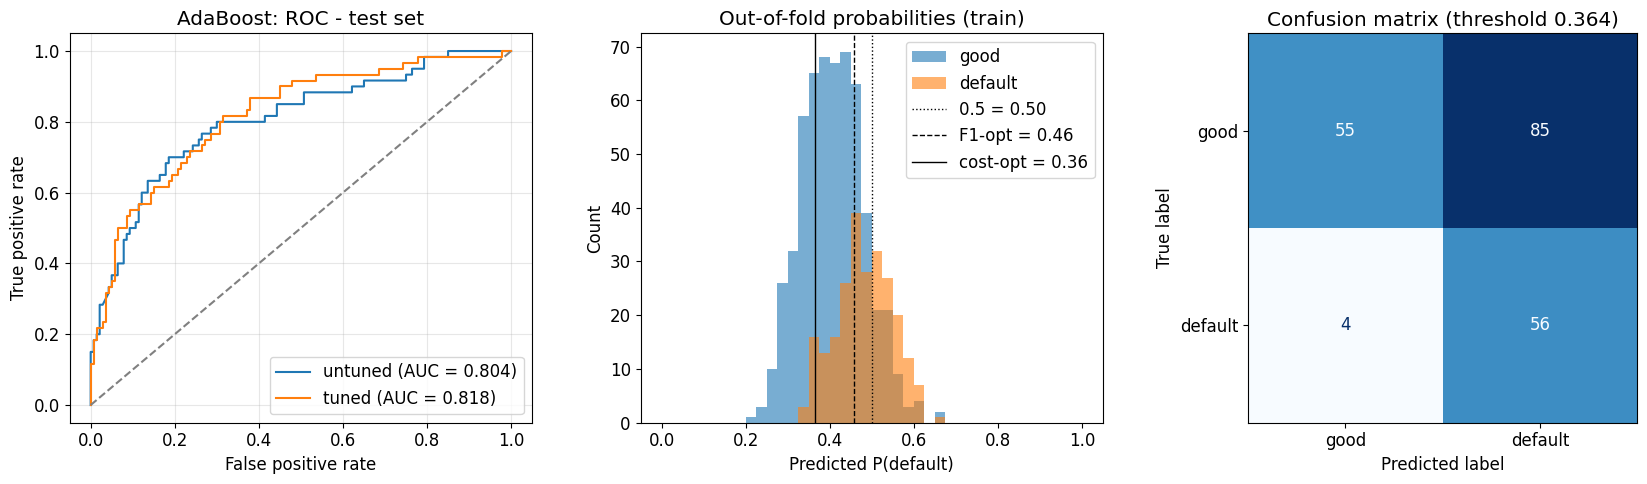

In [19]:
display(results_table([res_ada_default, op_ada["res_05"], op_ada["res_f1"], op_ada["res_cost"]],
                      fn_cost=FN_COST))
plot_operating_points(op_ada, [(res_ada_default, "untuned"), (op_ada["res_05"], "tuned")],
                      "AdaBoost", "adaboost_roc_confusion.png")

**Remark.** Test AUC is 0.818 (95% CI 0.748–0.880), the highest of the three models on the test set,
even though AdaBoost had the *lowest* CV AUC. The two estimates disagree by more than the gap between models.
This is another sign that the models cannot be separated on these data (Section 7).

The histogram shows the squeezed probabilities: every out-of-fold prediction lies between ≈ 0.2 and 0.67.
Thresholds must therefore be learned from the data. The cost-optimal threshold is 0.364, compared with 0.167 for calibrated
probabilities. At this threshold AdaBoost catches **56 of 60 defaulters (recall 0.93)** but rejects 85 of 140 good
clients, for a cost of **105**, down from 160 at 0.5.

## 7. Interpretation and model comparison
### 7.1 Logistic regression coefficients
Numeric features are standardised, so their coefficients are the change in log-odds of default per
one standard deviation. One-hot categories and engineered 0/1 flags are not scaled: their
coefficients compare the category with its absence. `odds_ratio = exp(coef)`.

0 of 70 coefficients shrunk exactly to zero


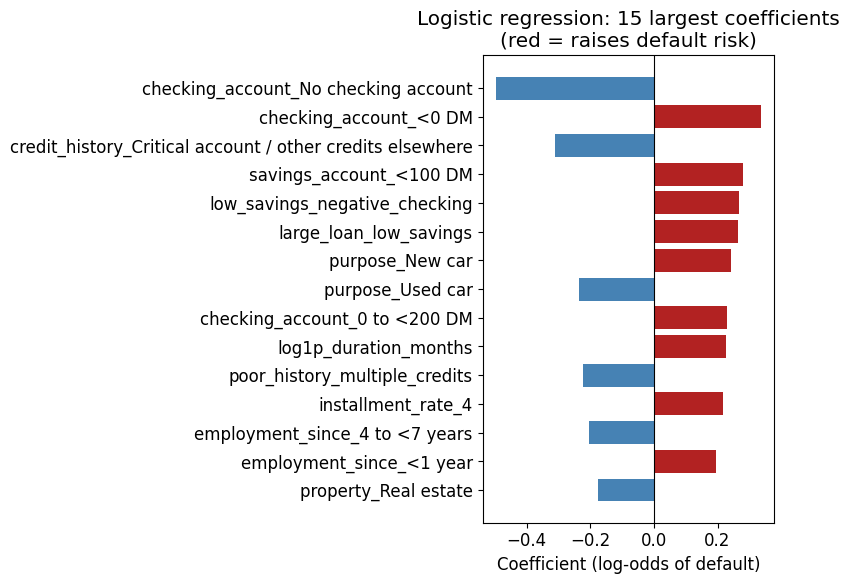

,feature,coef,odds_ratio
0,checking_account_No checking account,-0.496760,0.608499
1,checking_account_<0 DM,0.335792,1.399048
2,credit_history_Critical account / other credit...,-0.309643,0.733709
3,savings_account_<100 DM,0.281442,1.325039
4,low_savings_negative_checking,0.266263,1.305079
5,large_loan_low_savings,0.263116,1.300978
6,purpose_New car,0.241420,1.273055
7,purpose_Used car,-0.236645,0.789271
8,checking_account_0 to <200 DM,0.230355,1.259047
9,log1p_duration_months,0.228104,1.256216


In [20]:
feat_names = [n.split("__", 1)[-1] for n in lr_best.named_steps["preprocessing"].get_feature_names_out()]
coefs = pd.DataFrame({"feature": feat_names, "coef": lr_best.named_steps["classifier"].coef_.ravel()})
coefs["odds_ratio"] = np.exp(coefs["coef"])
coefs = coefs.reindex(coefs["coef"].abs().sort_values(ascending=False).index).reset_index(drop=True)
coefs.to_csv(OUT / "results/logreg_coefficients.csv", index=False)
print(f"{(coefs['coef'] == 0).sum()} of {len(coefs)} coefficients shrunk exactly to zero")

top = coefs.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["coef"], color=np.where(top["coef"] > 0, "firebrick", "steelblue"))
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Coefficient (log-odds of default)")
plt.title("Logistic regression: 15 largest coefficients\n(red = raises default risk)")
plt.tight_layout()
plt.savefig(OUT / "results/logreg_coefficients.png", dpi=200)
plt.show()
coefs.head(15)

### 7.2 Permutation importance (all three models)
Tree ensembles have no coefficients, so every model is put on a common scale. **Permutation
importance** measures how much the test AUC drops when one *original* input column is shuffled
(20 repeats). Shuffling a raw column also breaks every one-hot dummy and engineered flag built from
it, so each variable gets a single score. This shows what the model relies on, not causal effects,
and correlated columns can share credit.

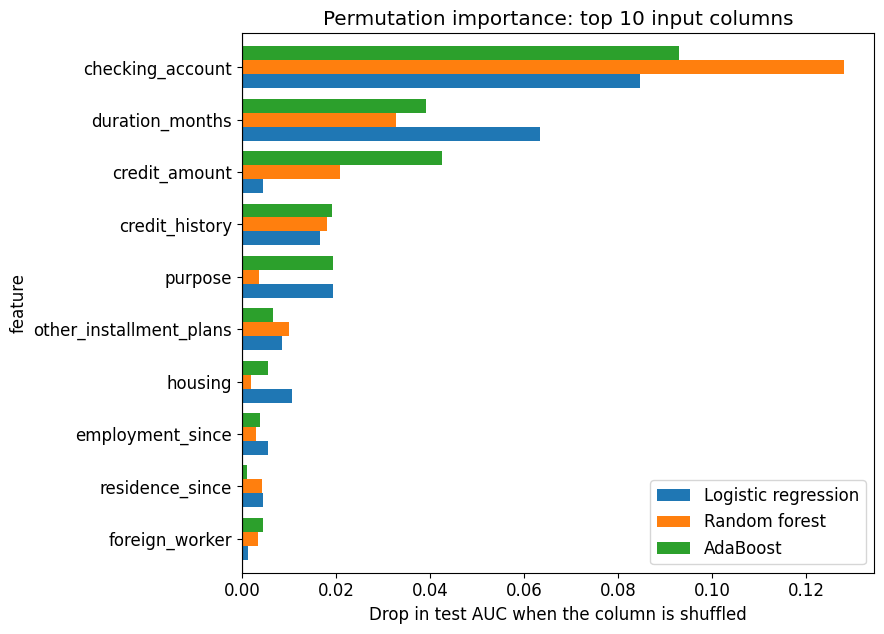

,Logistic regression,Random forest,AdaBoost
feature,,,
checking_account,0.085,0.128,0.093
duration_months,0.063,0.033,0.039
credit_amount,0.004,0.021,0.042
credit_history,0.017,0.018,0.019
purpose,0.019,0.004,0.019
other_installment_plans,0.008,0.010,0.007
housing,0.011,0.002,0.006
employment_since,0.006,0.003,0.004
residence_since,0.005,0.004,0.001


In [21]:
FINAL = {"Logistic regression": (lr_best, op_lr, "logreg"),
         "Random forest": (rf_best, op_rf, "rf"),
         "AdaBoost": (ada_best, op_ada, "adaboost")}

imps = {}
for m, (model, _, prefix) in FINAL.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pi = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=20,
                                    random_state=RANDOM_STATE, n_jobs=-1)
    imp = pd.DataFrame({"feature": X_test.columns, "auc_drop_mean": pi.importances_mean,
                        "auc_drop_std": pi.importances_std})
    imp = imp[(imp["auc_drop_mean"] != 0) | (imp["auc_drop_std"] != 0)]   # drop unused columns
    imp.sort_values("auc_drop_mean", ascending=False).to_csv(
        OUT / f"results/{prefix}_permutation_importance.csv", index=False)
    imps[m] = imp.set_index("feature")["auc_drop_mean"]

imp_all = pd.DataFrame(imps).fillna(0)
imp_all = imp_all.loc[imp_all.mean(axis=1).sort_values(ascending=False).index]

top = imp_all.head(10).iloc[::-1]
ax = top.plot.barh(figsize=(9, 6.5), width=0.8)
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="Drop in test AUC when the column is shuffled",
       title="Permutation importance: top 10 input columns")
plt.tight_layout()
plt.savefig(OUT / "results/permutation_importance.png", dpi=200)
plt.show()
imp_all.head(10).round(3)

**Remark.** All three models rely most on `checking_account` by a wide margin (AUC drop 0.09–0.13).
Loan `duration_months` comes second for all three and matters most to logistic regression (0.06).
The models then diverge in ways that match how they work:
- `credit_amount` matters to the tree models (0.02–0.04) but hardly to logistic regression (0.004). Its effect
  on default risk is non-linear and tied to duration, which trees can model and a linear model mostly absorbs
  through duration and the engineered amount/duration features.
- `purpose` matters to logistic regression and AdaBoost (≈ 0.02) but little to the random forest.
- `credit_history` is equally important to all three (≈ 0.02).

Beyond the top six columns the drops are about the size of their standard deviations and cannot be ranked reliably.

### 7.3 Summary table (tuned models at the cost-optimal threshold, FN:FP = 5:1)

In [22]:
GS = {"Logistic regression": gs_lr, "Random forest": gs_rf, "AdaBoost": gs_ada}
CVR = {"Logistic regression": cvr_lr, "Random forest": cvr_rf, "AdaBoost": cvr_ada}

rows = []
for m, (model, op, _) in FINAL.items():
    r, r05 = op["res_cost"], op["res_05"]
    tn, fp, fn, tp = r["confusion_matrix"].ravel()
    rows.append({
        "Model": m,
        "CV AUC (mean ± sd)": f"{GS[m].best_score_:.3f} ± {CVR[m].loc[0, 'std_test_score']:.3f}",
        "Test AUC [95% CI]": f"{r['auc']:.3f} [{op['ci'][0]:.3f}, {op['ci'][1]:.3f}]",
        "Cost-opt threshold": round(op["t_cost"], 3),
        "Recall (defaults)": round(r["recall"], 3),
        "Precision": round(r["precision"], 3),
        "Good clients rejected": f"{fp}/{tn + fp}",
        "Defaults missed": f"{fn}/{fn + tp}",
        "Cost @ cost-opt": r["cost"],
        "Cost @ 0.5": r05["cost"],
    })
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "results/model_comparison.csv", index=False)
summary

,Model,CV AUC (mean ± sd),Test AUC [95% CI],Cost-opt threshold,Recall (defaults),Precision,Good clients rejected,Defaults missed,Cost @ cost-opt,Cost @ 0.5
0,Logistic regression,0.769 ± 0.034,"0.816 [0.749, 0.877]",0.188,0.900,0.439,69/140,6/60,99.0,206.0
1,Random forest,0.789 ± 0.037,"0.803 [0.733, 0.870]",0.274,0.917,0.426,74/140,5/60,99.0,141.0
2,AdaBoost,0.768 ± 0.027,"0.818 [0.748, 0.880]",0.364,0.933,0.397,85/140,4/60,105.0,160.0


### 7.4 Are the AUC differences real?
Paired bootstrap on the 200 test rows: resample rows, recompute each model's AUC on the *same*
resample and take the difference. Pairing removes the variation that all models share, so this is
tighter than comparing the separate confidence intervals.

In [23]:
y_arr = y_test.values
proba = {m: op["res_05"]["y_proba"] for m, (_, op, _) in FINAL.items()}
names = list(proba)
pairs = [(a, b) for i, a in enumerate(names) for b in names[i + 1:]]
diffs = {p: [] for p in pairs}

rng = np.random.default_rng(RANDOM_STATE)
n = 0
while n < 2000:
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[idx].min() == y_arr[idx].max():
        continue
    auc = {m: roc_auc_score(y_arr[idx], proba[m][idx]) for m in names}
    for a, b in pairs:
        diffs[(a, b)].append(auc[a] - auc[b])
    n += 1

pd.DataFrame([{
    "Comparison": f"{a} − {b}",
    "AUC difference": round(roc_auc_score(y_arr, proba[a]) - roc_auc_score(y_arr, proba[b]), 3),
    "95% CI": f"[{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]",
    "P(diff > 0)": round(float(np.mean(np.array(d) > 0)), 2),
} for (a, b), d in diffs.items()])

,Comparison,AUC difference,95% CI,P(diff > 0)
0,Logistic regression − Random forest,0.014,"[-0.019, +0.044]",0.81
1,Logistic regression − AdaBoost,-0.001,"[-0.036, +0.033]",0.45
2,Random forest − AdaBoost,-0.015,"[-0.047, +0.014]",0.17


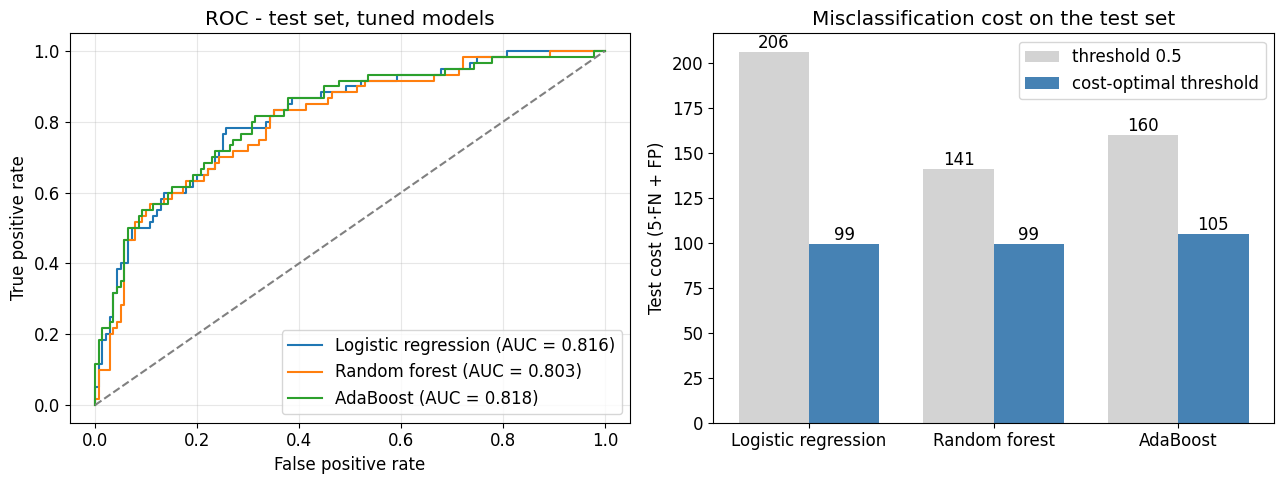

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for m in names:
    fpr, tpr, _ = roc_curve(y_arr, proba[m])
    axes[0].plot(fpr, tpr, label=f"{m} (AUC = {roc_auc_score(y_arr, proba[m]):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC - test set, tuned models")
axes[0].legend(loc="lower right"); axes[0].grid(alpha=0.3)

x, w = np.arange(len(names)), 0.38
b1 = axes[1].bar(x - w / 2, [FINAL[m][1]["res_05"]["cost"] for m in names], w,
                 label="threshold 0.5", color="lightgray")
b2 = axes[1].bar(x + w / 2, [FINAL[m][1]["res_cost"]["cost"] for m in names], w,
                 label="cost-optimal threshold", color="steelblue")
axes[1].bar_label(b1); axes[1].bar_label(b2)
axes[1].set_xticks(x, names)
axes[1].set(ylabel="Test cost (5·FN + FP)", title="Misclassification cost on the test set")
axes[1].legend()
plt.tight_layout()
plt.savefig(OUT / "results/model_comparison.png", dpi=200)
plt.show()

## 8. Conclusions
- **No model is clearly better at ranking borrowers.** Test AUCs are 0.803–0.818 and every paired AUC
  difference has a 95% CI that contains 0. Random forest has the best CV AUC (0.789) but the lowest
  test AUC, and AdaBoost the reverse. This 200-row test set cannot separate the three models.
- **The threshold matters far more than the model.** Moving from 0.5 to the cost-optimal threshold
  cuts the test cost by 30–50% for every model (LR 206 → 99, RF 141 → 99, AdaBoost 160 → 105).
  All three models catch 90–93% of defaulters, at the price of rejecting about half of the good clients.
- **Class imbalance.** Reweighting classes during training barely changed the forest's AUC and hurt
  AdaBoost's. The effective lever for the 30% default rate and the 5:1 cost ratio is the decision threshold.
- **The models agree on the main drivers:** checking-account status first, then loan duration and credit
  history. The tree models also use the loan amount, which logistic regression barely needs (Section 7.2).
- **Recommendation:** at equal cost, logistic regression is the simplest model to explain and
  audit, with coefficients and odds ratios. The tree ensembles do not earn their extra complexity on this dataset.

## Saved outputs
Tuned models, test and out-of-fold probabilities, and one metrics file per model. The metrics
files have the same format as before, so existing code that reads `outputs/results/*_metrics.json`
keeps working.

In [25]:
def to_json(v):
    return v if isinstance(v, (str, int, type(None))) else float(v)

defaults = {"logreg": [res_naive, res_lr_default], "rf": [res_rf_default], "adaboost": [res_ada_default]}
for m, (model, op, prefix) in FINAL.items():
    joblib.dump(model, OUT / f"models/{prefix}_best.joblib")
    gs, cvr = GS[m], CVR[m]
    summary_json = {
        "model": type(model.named_steps["classifier"]).__name__,
        "best_params": {k.replace("classifier__", ""): to_json(v) for k, v in gs.best_params_.items()},
        "cv_auc_mean": float(gs.best_score_), "cv_auc_std": float(cvr.loc[0, "std_test_score"]),
        "cv_train_auc_mean": float(cvr.loc[0, "mean_train_score"]),
        "test_auc_ci95": op["ci"], "fn_cost": FN_COST,
        "thresholds": {"default": 0.5, "f1_opt": op["t_f1"], "cost_opt": op["t_cost"]},
        "results": {r["name"]: metrics_only(r)
                    for r in defaults[prefix] + [op["res_05"], op["res_f1"], op["res_cost"]]},
    }
    (OUT / f"results/{prefix}_metrics.json").write_text(json.dumps(summary_json, indent=2))
print("Saved models to", OUT / "models", "| metrics and figures to", OUT / "results",
      "| probabilities to", OUT / "predictions")

Saved models to /Users/sarah/Desktop/DSE4212-Creditscoring/outputs/models | metrics and figures to /Users/sarah/Desktop/DSE4212-Creditscoring/outputs/results | probabilities to /Users/sarah/Desktop/DSE4212-Creditscoring/outputs/predictions


## Notes for the report
- The test set is small (200 customers, 60 defaults), so compare models using the AUC confidence
  intervals and the paired bootstrap (Section 7.4), not the point estimates.
- Thresholds were set on out-of-fold training predictions. The test set was used once, for the final numbers.
- `gender_group` and `age_group` are sensitive attributes and are not model inputs. Use them only
  for the optional fairness analysis (see `notebooks/German_Credit_Clean.ipynb`).